# Training an MLP on sin(x) data

This notebook contains experiments with training a shallow neural network of the multilayer perceptron (MLP) type on simple data using least-squares loss, supported by automated gradient computation via JAX, and doing optimization via Open Interfaces.

**Setup**:
- Training data of size 101: $x\in[-2\pi, 2\pi]$, $y=\sin(x)$, sampled uniformly
- Multilayer perceptron model with 50 hidden neurons
- L-BFGS algorithm implemented in SciPy and Optim.jl
- Convergence criterion is $|f_k+1 - f_k| \leq \mathrm{ftol}$, which is available in both implementations, $\mathrm{ftol} \approx 2.22e-9$

**Outcomes**:
- L2 error on test data (which are computed at $x_i + \frac12\Delta x$)
- Plot of the training data with points of the predictions
- Time-to-solution (after warming up Julia, as it adds overhead about 7-10 seconds)

In [1]:
!which python

/home/dima/sw/miniforge3/envs/um02-open-interfaces/bin/python


In [2]:
!echo $PYTHONPATH

src/mlpexample:/home/dima/Work/um02-open-interfaces/oif/interfaces/python:/home/dima/Work/um02-open-interfaces/lang_python/oif:/home/dima/Work/um02-open-interfaces/lang_python/oif_interfaces:/home/dima/Work/um02-open-interfaces/lang_python/oif_impl:/home/dima/Work/um02-open-interfaces/build:


In [5]:
from IPython.display import Image

std of parameters vector:  0.5412431915527011
[dispatch] Configuration file: /home/dima/Work/um02-open-interfaces/lang_python/oif_impl/openinterfaces/_impl/optim/scipy_optimize/scipy_optimize.conf
[dispatch] Backend name: python
[dispatch] Implementation details: 'openinterfaces._impl.optim.scipy_optimize.scipy_optimize ScipyOptimize'
[bridge_python] Backend is already initialized
[bridge_python] libpython path: /home/dima/sw/miniforge3/envs/um02-open-interfaces/lib
[bridge_python] Loading /home/dima/sw/miniforge3/envs/um02-open-interfaces/lib/libpython3.13.so
[bridge_python] /home/dima/sw/miniforge3/envs/um02-open-interfaces/bin/python
[bridge_python] 3.13.2 | packaged by conda-forge | (main, Feb 17 2025, 14:10:22) [GCC 13.3.0]
[bridge_python] NumPy version:  2.2.4
[bridge_python] Provided module name: 'openinterfaces._impl.optim.scipy_optimize.scipy_optimize'
[bridge_python] Provided class name: 'ScipyOptimize'
  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success

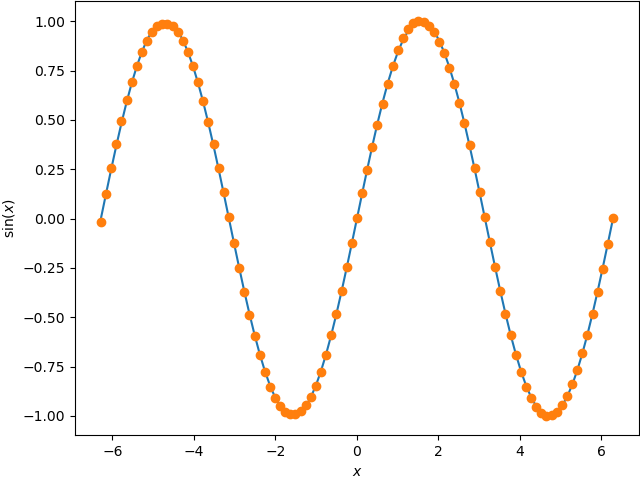

In [12]:
!python bin/train_sin_nn.py --impl=scipy_optimize
Image("_output/current/sin_func.png")

std of parameters vector:  0.5412431915527011
[dispatch] Configuration file: /home/dima/Work/um02-open-interfaces/lang_julia/_impl/optim/optim_jl/optim_jl.conf
[dispatch] Backend name: julia
[dispatch] Implementation details: 'optim/optim_jl/optim_jl.jl OptimJl'
[bridge_julia] Provided module filename: 'optim/optim_jl/optim_jl.jl'
[bridge_julia] Provided module name: 'OptimJl'
[bridge_julia] Found module file '/home/dima/Work/um02-open-interfaces/lang_julia/_impl/optim/optim_jl/optim_jl.jl'
[optim::optim_jl] To check available configuration options, see https://julianlsolvers.github.io/Optim.jl/stable/user/config/
res =  * Status: success

 * Candidate solution
    Final objective value:     5.931150e-05

 * Found with
    Algorithm:     L-BFGS

 * Convergence measures
    |x - x'|               = 8.25e-06 ≰ 0.0e+00
    |x - x'|/|x'|          = 6.33e-07 ≰ 0.0e+00
    |f(x) - f(x')|         = 1.59e-09 ≤ 2.2e-09
    |f(x) - f(x')|/|f(x')| = 2.68e-05 ≰ 0.0e+00
    |g(x)|                 =

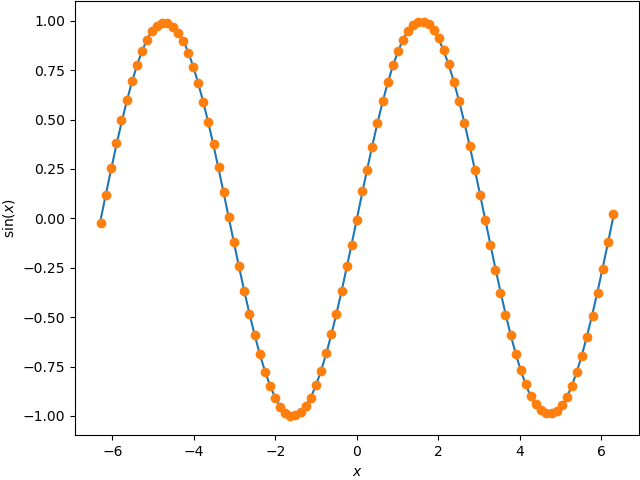

In [13]:
!python bin/train_sin_nn.py --impl=optim_jl
Image("_output/current/sin_func.png")

# Results

- Both results give L2 prediction error of 0.16
- measured runtime with SciPy is 16 seconds
- measured runtime with Optim.jl (reported by it) is 19 seconds, although I measured it to be 25 seconds
- SciPy:
    ```
     nfev: 995
     njev: 995
     ```
- Optim.jl:
```
    f(x) calls:    2827
    ∇f(x) calls:   2827
```
the discrepancy between the number of evaluations is crazy.